# 🎓 Smart Outcome Predictor — Ensemble Learning Project

**Role:** Junior Machine Learning Engineer at an EdTech analytics company  
**Dataset:** `Smart_Outcome_Predictor_Dataset_5200.xlsx`  
**Goal:** Predict (1) whether a student completes an online course and (2) the student's final score.

> 👋 Welcome! In this notebook, we will build the project step by step. Every section explains what we are doing, why it matters, and what the results mean in a real education setting.

## 🗺️ Project workflow

```text
Load data → Understand & clean → Prepare features → Split data
     ↓
Baseline models → Bagging → AdaBoost & XGBoost
     ↓
Voting & Stacking → Evaluate fairly → Business recommendation
     ↓
Save model files → Streamlit app / GitHub / video submission
```

**Important:** The project brief asks for both classification and regression, and it specifically requires evaluation tables, clearly labelled charts, short interpretations, and a final deployment recommendation.

## 1. Import the tools we need 🧰

We will use familiar tools from the course: **pandas** for data, **matplotlib** for charts, and **scikit-learn** for splitting data, preprocessing, training models, and evaluating results. XGBoost is included because it is specifically named in the project brief.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingClassifier, BaggingRegressor,
    AdaBoostClassifier, AdaBoostRegressor,
    VotingClassifier, StackingClassifier, StackingRegressor
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.naive_bayes import GaussianNB
try:
    from xgboost import XGBClassifier, XGBRegressor
except ModuleNotFoundError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "xgboost"])
    from xgboost import XGBClassifier, XGBRegressor
import joblib

RANDOM_STATE = 42
print("✅ Libraries imported successfully!")

✅ Libraries imported successfully!


## 2. Load the dataset 📂

Keep the Excel file in the **same folder** as this notebook. We use the exact dataset supplied for this project.

In [3]:
DATA_FILE = "Smart_Outcome_Predictor_Dataset_5200.xlsx"

if not os.path.exists(DATA_FILE):
    # A helpful fallback for this prepared notebook's original runtime.
    possible_paths = [
        "/mnt/data/Smart_Outcome_Predictor_Dataset_5200.xlsx"
    ]
    DATA_FILE = next((p for p in possible_paths if os.path.exists(p)), DATA_FILE)

df = pd.read_excel(DATA_FILE)
print(f"Dataset loaded: {df.shape[0]:,} rows and {df.shape[1]} columns")
display(df.head())

Dataset loaded: 5,200 rows and 19 columns


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


### What does one row represent?

One row represents one student record. The dataset contains demographic information, course details, engagement activity, assessment measures, and two outcomes: `completion_status` and `final_score`.

## 3. Understand the data 🔍

First, inspect column names, data types, missing values, and the two target variables. This helps us catch issues before training.

In [4]:
display(df.info())
display(df.describe(include="all").T)
missing_summary = df.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0].to_frame("Missing values"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   student_id             5200 non-null   int64         
 1   age                    5200 non-null   int64         
 2   country_region         5200 non-null   object        
 3   device_type            5200 non-null   object        
 4   education_background   5200 non-null   object        
 5   course_level           5200 non-null   object        
 6   course_category        5200 non-null   object        
 7   course_start_date      5200 non-null   datetime64[ns]
 8   week_of_year           5200 non-null   int64         
 9   sessions               5200 non-null   int64         
 10  time_spent_hours       5088 non-null   float64       
 11  videos_watched         5200 non-null   int64         
 12  quiz_attempts          5200 non-null   int64         
 13  ass

None

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
student_id,5200.0,NaN,NaN,NaN,702600.5,700001.0,701300.75,702600.5,703900.25,705200.0,1501.255031
age,5200.0,NaN,NaN,NaN,24.339615,16.0,20.0,24.0,28.0,45.0,5.578864
country_region,5200,5,Asia,1984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_type,5200,3,Mobile,3020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education_background,5200,4,Undergrad,2311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
course_level,5200,3,Beginner,2264,NaN,NaN,NaN,NaN,NaN,NaN,NaN
course_category,5200,5,Data,1525,NaN,NaN,NaN,NaN,NaN,NaN,NaN
course_start_date,5200,NaN,NaN,NaN,2024-07-02 09:45:24.923076864,2024-01-01 00:00:00,2024-04-02 00:00:00,2024-07-02 00:00:00,2024-10-01 00:00:00,2024-12-30 00:00:00,NaN
week_of_year,5200.0,NaN,NaN,NaN,26.621538,1.0,14.0,27.0,40.0,52.0,15.007731
sessions,5200.0,NaN,NaN,NaN,19.121923,1.0,11.0,17.0,25.0,94.0,10.726708


,Missing values
time_spent_hours,112
avg_quiz_score,81
attendance_rate,80


In [5]:
print("Completion status counts:")
display(df["completion_status"].value_counts().sort_index().to_frame("Students"))
print("\nFinal score summary:")
display(df["final_score"].describe().to_frame("Final score"))

Completion status counts:


,Students
completion_status,
0,3248
1,1952



Final score summary:


,Final score
count,5200.000000
mean,74.821615
std,13.531829
min,35.200000
25%,64.700000
50%,74.100000
75%,84.900000
max,100.000000


### 🧠 Quick interpretation

- `completion_status` is a **classification target**: `0 = Not Completed`, `1 = Completed`.
- `final_score` is a **regression target**, with values between 0 and 100 in this dataset.
- Some engagement and assessment columns contain missing values. We will impute those values inside the preprocessing pipeline rather than deleting lots of student records.

## 4. Prepare features and targets 🧹

We must not give a model the answer it is supposed to predict. For that reason, we remove `student_id` and `course_start_date` from the input features, and we exclude **both outcome columns** from the feature set. This also prevents the classification model from using `final_score` as a shortcut.

Categorical columns will be one-hot encoded. Numeric missing values will be filled with the median. The same preprocessing is fitted on the training data only through a scikit-learn pipeline, reducing data leakage.

In [6]:
TARGET_CLASS = "completion_status"
TARGET_REG = "final_score"

# IDs are identifiers, not useful general learning signals. We omit raw dates
# to keep the project focused on techniques covered in the course.
drop_from_features = ["student_id", "course_start_date", TARGET_CLASS, TARGET_REG]
X = df.drop(columns=drop_from_features)
y_class = df[TARGET_CLASS].astype(int)
y_reg = df[TARGET_REG].astype(float)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Feature columns:", X.shape[1])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nClassification target:", TARGET_CLASS)
print("Regression target:", TARGET_REG)

Feature columns: 15
Numeric features: ['age', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate']
Categorical features: ['country_region', 'device_type', 'education_background', 'course_level', 'course_category']

Classification target: completion_status
Regression target: final_score


### 🧪 Train–test split

We keep 20% of the data for the final test. `stratify=y_class` preserves the completion/not-completion proportions in the classification split. The same row split is used for both tasks so the comparisons are easy to follow.

In [7]:
X_train, X_test, y_class_train, y_class_test = train_test_split(
    X, y_class, test_size=0.20, random_state=RANDOM_STATE, stratify=y_class
)
# Use the same row indices for the regression task.
y_reg_train = y_reg.loc[y_class_train.index]
y_reg_test = y_reg.loc[y_class_test.index]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining completion rate:", round(y_class_train.mean() * 100, 2), "%")
print("Testing completion rate:", round(y_class_test.mean() * 100, 2), "%")

Training rows: 4160
Testing rows: 1040

Training completion rate: 37.55 %
Testing completion rate: 37.5 %


In [8]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("✅ Preprocessing pipeline is ready.")

✅ Preprocessing pipeline is ready.


## 5. Baseline models 🌱

A baseline is our starting point. We compare ensemble models against a single decision tree, so we can see whether combining learners actually helps on this dataset.

In [9]:
baseline_classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))
])
baseline_regressor = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))
])

baseline_classifier.fit(X_train, y_class_train)
baseline_regressor.fit(X_train, y_reg_train)

print("Baseline classification accuracy:",
      round(accuracy_score(y_class_test, baseline_classifier.predict(X_test)), 4))
base_reg_pred = baseline_regressor.predict(X_test)
print("Baseline regression MAE:",
      round(mean_absolute_error(y_reg_test, base_reg_pred), 3))
print("Baseline regression RMSE:",
      round(np.sqrt(mean_squared_error(y_reg_test, base_reg_pred)), 3))
print("Baseline regression R²:",
      round(r2_score(y_reg_test, base_reg_pred), 3))

Baseline classification accuracy: 0.7029
Baseline regression MAE: 8.775
Baseline regression RMSE: 10.999
Baseline regression R²: 0.335


## 6. Part C — Bagging (Bootstrap Aggregating) 🧺

Bagging trains multiple versions of a model on resampled training data, then combines their predictions. This often reduces the instability of a single decision tree.

In [10]:
bagging_classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
        n_estimators=50, random_state=RANDOM_STATE, n_jobs=1
    ))
])
bagging_regressor = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE),
        n_estimators=50, random_state=RANDOM_STATE, n_jobs=1
    ))
])

bagging_classifier.fit(X_train, y_class_train)
bagging_regressor.fit(X_train, y_reg_train)
print("✅ Bagging classifier and regressor trained.")

✅ Bagging classifier and regressor trained.


## 7. Part D — Boosting: AdaBoost ⚡

Boosting builds learners sequentially. Each new learner gives extra attention to examples that earlier learners handled poorly. AdaBoost is the course's introductory boosting algorithm.

In [11]:
adaboost_classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
        n_estimators=60, learning_rate=0.5, random_state=RANDOM_STATE
    ))
])
adaboost_regressor = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE),
        n_estimators=60, learning_rate=0.5, random_state=RANDOM_STATE
    ))
])

adaboost_classifier.fit(X_train, y_class_train)
adaboost_regressor.fit(X_train, y_reg_train)
print("✅ AdaBoost classifier and regressor trained.")

✅ AdaBoost classifier and regressor trained.


## 8. Part D — Boosting: XGBoost 🚀

XGBoost is a gradient-boosting implementation that adds regularization and efficient training options. We use a modest number of trees to keep this project practical within the available time.

In [12]:
xgb_classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=120, max_depth=3, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        objective="binary:logistic", eval_metric="logloss",
        random_state=RANDOM_STATE, n_jobs=1
    ))
])
xgb_regressor = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=120, max_depth=3, learning_rate=0.08,
        subsample=0.9, colsample_bytree=0.9,
        objective="reg:squarederror",
        random_state=RANDOM_STATE, n_jobs=1
    ))
])

xgb_classifier.fit(X_train, y_class_train)
xgb_regressor.fit(X_train, y_reg_train)
print("✅ XGBoost classifier and regressor trained.")

✅ XGBoost classifier and regressor trained.


## 9. Part E — Voting Classifiers 🗳️

Voting combines predictions from different model types. **Hard voting** chooses the class with the most votes. **Soft voting** averages predicted probabilities and chooses the class with the higher average probability.

We use decision trees, logistic regression, and Gaussian Naive Bayes as different base learners. All models receive the same prepared features.

In [13]:
voting_estimators = [
    ("tree", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)),
    ("logistic", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ("naive_bayes", GaussianNB())
]

hard_voting = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", VotingClassifier(estimators=voting_estimators, voting="hard"))
])
soft_voting = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", VotingClassifier(estimators=voting_estimators, voting="soft"))
])

hard_voting.fit(X_train, y_class_train)
soft_voting.fit(X_train, y_class_train)
print("✅ Hard and soft voting models trained.")

✅ Hard and soft voting models trained.


## 10. Part E — Stacking Ensembles 🏗️

Stacking trains a second-level model (the **meta-learner**) to learn how to combine predictions from several base models. Here, logistic regression is the classification meta-learner and Ridge regression is the regression meta-learner.

In [14]:
stacking_classifier = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", StackingClassifier(
        estimators=[
            ("tree", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)),
            ("logistic", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
            ("naive_bayes", GaussianNB())
        ],
        final_estimator=LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        cv=3, n_jobs=1
    ))
])
stacking_regressor = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", StackingRegressor(
        estimators=[
            ("tree", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE)),
            ("ridge", Ridge()),
            ("adaboost", AdaBoostRegressor(
                estimator=DecisionTreeRegressor(max_depth=2, random_state=RANDOM_STATE),
                n_estimators=30, random_state=RANDOM_STATE
            ))
        ],
        final_estimator=Ridge(), cv=3, n_jobs=1
    ))
])

stacking_classifier.fit(X_train, y_class_train)
stacking_regressor.fit(X_train, y_reg_train)
print("✅ Stacking classifier and regressor trained.")

✅ Stacking classifier and regressor trained.


## 11. Part F — Evaluate all classification models 📊

We report Accuracy, Precision, Recall, F1-score, and ROC-AUC as required. ROC-AUC uses predicted probabilities when available. A higher score is generally better for all five metrics, but precision and recall can involve a trade-off.

In [15]:
classification_models = {
    "Decision Tree (Baseline)": baseline_classifier,
    "Bagging": bagging_classifier,
    "AdaBoost": adaboost_classifier,
    "XGBoost": xgb_classifier,
    "Hard Voting": hard_voting,
    "Soft Voting": soft_voting,
    "Stacking": stacking_classifier
}

classification_rows = []
for name, model in classification_models.items():
    pred = model.predict(X_test)
    try:
        probability = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_class_test, probability)
    except (AttributeError, ValueError):
        # Hard voting returns class labels rather than probabilities.
        # This gives a coarse AUC estimate; soft voting's probability-based AUC is more informative.
        auc = roc_auc_score(y_class_test, pred)
    classification_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_class_test, pred),
        "Precision": precision_score(y_class_test, pred, zero_division=0),
        "Recall": recall_score(y_class_test, pred, zero_division=0),
        "F1-score": f1_score(y_class_test, pred, zero_division=0),
        "ROC-AUC": auc
    })

classification_results = pd.DataFrame(classification_rows).sort_values(
    by="F1-score", ascending=False
).reset_index(drop=True)
display(classification_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,XGBoost,0.7375,0.6778,0.5718,0.6203,0.7890
1,Stacking,0.7365,0.6790,0.5641,0.6162,0.7942
2,Hard Voting,0.7394,0.6951,0.5436,0.6101,0.7003
3,Bagging,0.7327,0.6761,0.5513,0.6073,0.7800
4,Soft Voting,0.7327,0.6783,0.5462,0.6051,0.7866
5,AdaBoost,0.7337,0.6817,0.5436,0.6049,0.7870
6,Decision Tree (Baseline),0.7029,0.6588,0.4308,0.5209,0.7547


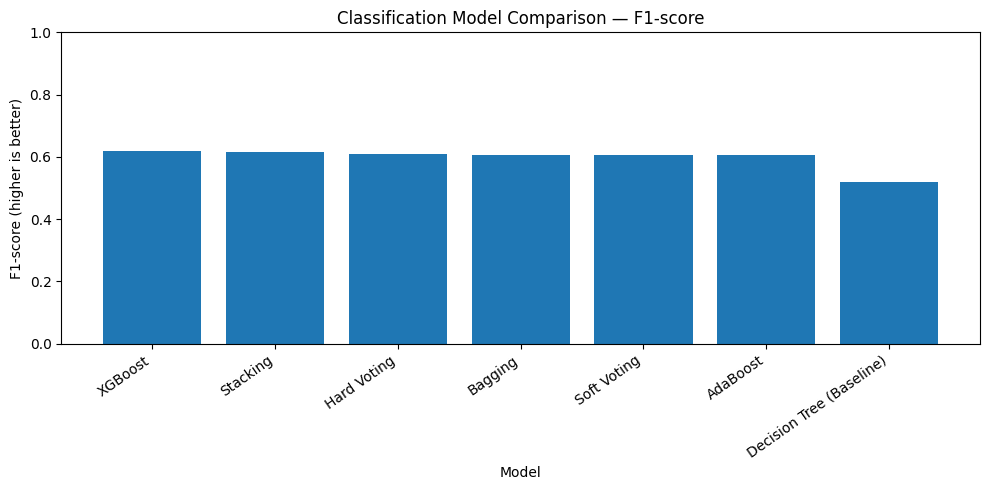

📌 Best model by F1-score: XGBoost
Interpretation: F1-score balances precision and recall. Use this result as the leading candidate,
then check ROC-AUC and the confusion matrix before recommending deployment.


In [16]:
plt.figure(figsize=(10, 5))
plt.bar(classification_results["Model"], classification_results["F1-score"])
plt.title("Classification Model Comparison — F1-score")
plt.ylabel("F1-score (higher is better)")
plt.xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

best_classifier_name = classification_results.iloc[0]["Model"]
print(f"📌 Best model by F1-score: {best_classifier_name}")
print("Interpretation: F1-score balances precision and recall. Use this result as the leading candidate,")
print("then check ROC-AUC and the confusion matrix before recommending deployment.")

### Confusion matrix and classification report

The confusion matrix helps us see completed students predicted correctly, students missed, and false alarms. The classification report provides precision, recall, and F1-score for each class.

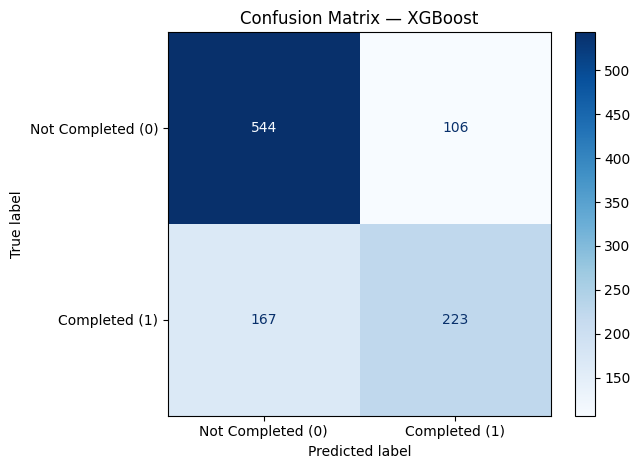

               precision    recall  f1-score   support

Not Completed       0.77      0.84      0.80       650
    Completed       0.68      0.57      0.62       390

     accuracy                           0.74      1040
    macro avg       0.72      0.70      0.71      1040
 weighted avg       0.73      0.74      0.73      1040



In [17]:
best_classifier = classification_models[best_classifier_name]
ConfusionMatrixDisplay.from_estimator(
    best_classifier, X_test, y_class_test,
    display_labels=["Not Completed (0)", "Completed (1)"],
    cmap="Blues", values_format="d"
)
plt.title(f"Confusion Matrix — {best_classifier_name}")
plt.tight_layout()
plt.show()

print(classification_report(
    y_class_test, best_classifier.predict(X_test),
    target_names=["Not Completed", "Completed"], zero_division=0
))

## 12. Part F — Evaluate all regression models 📈

For regression, lower MAE and RMSE are better; R² closer to 1 indicates that the model explains more variation in final scores. RMSE penalizes larger errors more strongly than MAE.

In [18]:
regression_models = {
    "Decision Tree (Baseline)": baseline_regressor,
    "Bagging": bagging_regressor,
    "AdaBoost": adaboost_regressor,
    "XGBoost": xgb_regressor,
    "Stacking": stacking_regressor
}

regression_rows = []
for name, model in regression_models.items():
    pred = model.predict(X_test)
    regression_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_reg_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_reg_test, pred)),
        "R² Score": r2_score(y_reg_test, pred)
    })

regression_results = pd.DataFrame(regression_rows).sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)
display(regression_results.round(4))

,Model,MAE,RMSE,R² Score
0,Stacking,8.0795,10.0360,0.4467
1,XGBoost,8.1215,10.1274,0.4366
2,Bagging,8.4071,10.4313,0.4023
3,AdaBoost,8.9199,10.9045,0.3468
4,Decision Tree (Baseline),8.7746,10.9993,0.3354


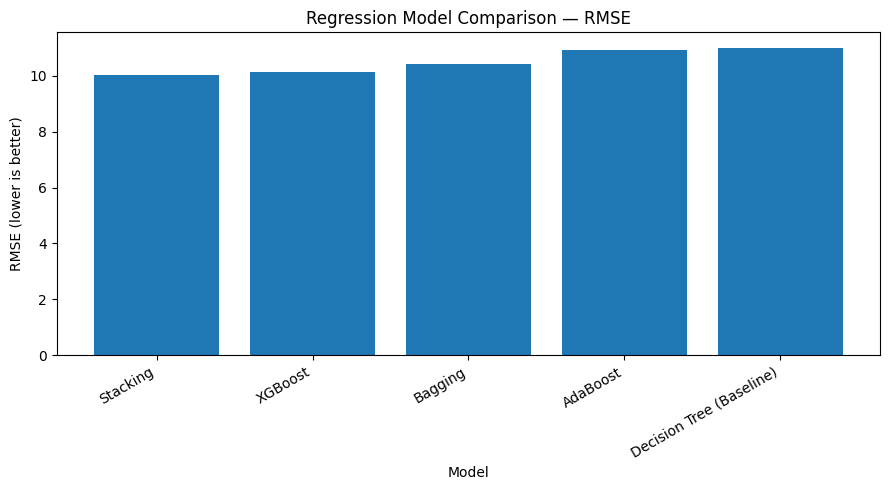

📌 Best model by RMSE: Stacking
Interpretation: RMSE is expressed in final-score points. Smaller values mean predictions
are closer to the students' actual scores on average, with larger errors penalized more.


In [19]:
plt.figure(figsize=(9, 5))
plt.bar(regression_results["Model"], regression_results["RMSE"])
plt.title("Regression Model Comparison — RMSE")
plt.ylabel("RMSE (lower is better)")
plt.xlabel("Model")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

best_regressor_name = regression_results.iloc[0]["Model"]
print(f"📌 Best model by RMSE: {best_regressor_name}")
print("Interpretation: RMSE is expressed in final-score points. Smaller values mean predictions")
print("are closer to the students' actual scores on average, with larger errors penalized more.")

## 13. Visualise predicted vs actual final scores 🎯

A good regression model should place predictions near the diagonal line. Points far from that line represent larger prediction errors.

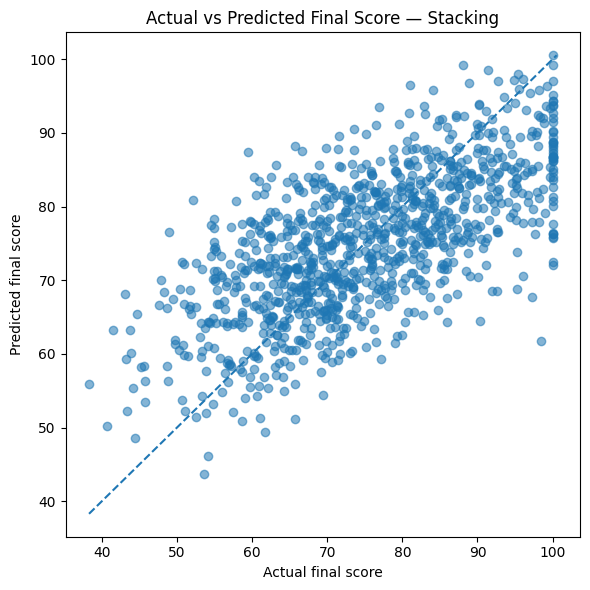

Interpretation: points closer to the dashed diagonal indicate more accurate score predictions.


In [20]:
best_regressor = regression_models[best_regressor_name]
reg_predictions = best_regressor.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_reg_test, reg_predictions, alpha=0.55)
low = min(y_reg_test.min(), reg_predictions.min())
high = max(y_reg_test.max(), reg_predictions.max())
plt.plot([low, high], [low, high], linestyle="--")
plt.title(f"Actual vs Predicted Final Score — {best_regressor_name}")
plt.xlabel("Actual final score")
plt.ylabel("Predicted final score")
plt.tight_layout()
plt.show()
print("Interpretation: points closer to the dashed diagonal indicate more accurate score predictions.")

## 14. Part G — Final comparison and business interpretation 🧑‍💼

We will use the test results, not guesses, to select candidate models. For completion prediction, F1-score is our primary sorting metric because it balances precision and recall. For final-score prediction, we use RMSE.

In [21]:
print("CLASSIFICATION LEADER")
display(classification_results.head(3).round(4))
print("\nREGRESSION LEADER")
display(regression_results.head(3).round(4))

print("\nBusiness interpretation:")
print(f"- Completion prediction candidate: {best_classifier_name}.")
print(f"- Final-score prediction candidate: {best_regressor_name}.")
print("- The completion model could help an EdTech team identify students who may need support.")
print("- The score model could help estimate likely performance and guide additional learning support.")
print("- Before deployment, validate on future cohorts, review fairness across student groups, and monitor performance.")

CLASSIFICATION LEADER


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,XGBoost,0.7375,0.6778,0.5718,0.6203,0.7890
1,Stacking,0.7365,0.6790,0.5641,0.6162,0.7942
2,Hard Voting,0.7394,0.6951,0.5436,0.6101,0.7003



REGRESSION LEADER


,Model,MAE,RMSE,R² Score
0,Stacking,8.0795,10.0360,0.4467
1,XGBoost,8.1215,10.1274,0.4366
2,Bagging,8.4071,10.4313,0.4023



Business interpretation:
- Completion prediction candidate: XGBoost.
- Final-score prediction candidate: Stacking.
- The completion model could help an EdTech team identify students who may need support.
- The score model could help estimate likely performance and guide additional learning support.
- Before deployment, validate on future cohorts, review fairness across student groups, and monitor performance.


### Theory recap (2–4 lines each) 🧠

1. **Ensemble learning:** combines predictions from multiple models. It can improve generalisation because different learners may make different errors.
2. **Bagging vs boosting vs voting:** bagging trains models on bootstrap samples in parallel; boosting adds learners sequentially; voting combines predictions from different fitted models.
3. **Bias–variance trade-off:** bias is error from overly simple assumptions; variance is sensitivity to training data. Ensembles can reduce variance or improve fit, depending on the method and model settings.
4. **Voting vs stacking:** voting uses a fixed rule such as majority vote or average probabilities. Stacking trains a meta-learner to combine base-model predictions.
5. **AdaBoost vs XGBoost:** AdaBoost reweights difficult examples so later weak learners focus on them. XGBoost uses gradient boosting with regularisation and other efficiency features.

## 15. Save the best candidate models 💾

These files are useful for the Streamlit application and for keeping a copy of the trained pipelines. The preprocessing steps are saved with each model, so the same encoding and imputation can be reused at prediction time.

In [22]:
joblib.dump(best_classifier, "best_completion_model.joblib")
joblib.dump(best_regressor, "best_final_score_model.joblib")
print("Saved: best_completion_model.joblib")
print("Saved: best_final_score_model.joblib")

Saved: best_completion_model.joblib
Saved: best_final_score_model.joblib


## 16. Create a simple Streamlit app file 🌐

This cell writes a starter `streamlit_app.py`. It loads the saved models and lets a user enter the student features used by the notebook. Run this cell after the models have been saved. To run locally, install Streamlit and launch `streamlit run streamlit_app.py`.

**Deployment note:** creating this file does not publish it online. You still need to upload the files to GitHub and deploy the app using a Streamlit-compatible hosting service to obtain a live URL.

In [23]:
app_code = r'''
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(page_title="Smart Outcome Predictor", page_icon="🎓", layout="centered")
st.title("🎓 Smart Outcome Predictor")
st.write("Estimate course completion and final performance from student engagement details.")

completion_model = joblib.load("best_completion_model.joblib")
score_model = joblib.load("best_final_score_model.joblib")

st.subheader("Enter student details")
age = st.number_input("Age", min_value=10, max_value=100, value=25)
country_region = st.selectbox("Country / region", ["Africa", "Americas", "Asia", "Europe", "Oceania"])
device_type = st.selectbox("Device type", ["Laptop", "Mobile", "Tablet", "Desktop"])
education_background = st.selectbox("Education background", ["HighSchool", "Undergrad", "Graduate", "WorkingPro"])
course_level = st.selectbox("Course level", ["Beginner", "Intermediate", "Advanced"])
course_category = st.selectbox("Course category", ["Business", "Data", "Design", "Marketing", "Programming"])
week_of_year = st.slider("Week of year", 1, 53, 20)
sessions = st.number_input("Sessions", min_value=0, value=8)
time_spent_hours = st.number_input("Time spent (hours)", min_value=0.0, value=15.0)
videos_watched = st.number_input("Videos watched", min_value=0, value=10)
quiz_attempts = st.number_input("Quiz attempts", min_value=0, value=4)
assignments_submitted = st.number_input("Assignments submitted", min_value=0, value=4)
forum_posts = st.number_input("Forum posts", min_value=0, value=2)
avg_quiz_score = st.slider("Average quiz score", 0.0, 100.0, 70.0)
attendance_rate = st.slider("Attendance rate", 0.0, 1.0, 0.8)

if st.button("Predict outcome"):
    student = pd.DataFrame([{
        "age": age, "country_region": country_region, "device_type": device_type,
        "education_background": education_background, "course_level": course_level,
        "course_category": course_category, "week_of_year": week_of_year,
        "sessions": sessions, "time_spent_hours": time_spent_hours,
        "videos_watched": videos_watched, "quiz_attempts": quiz_attempts,
        "assignments_submitted": assignments_submitted, "forum_posts": forum_posts,
        "avg_quiz_score": avg_quiz_score, "attendance_rate": attendance_rate
    }])
    completion = int(completion_model.predict(student)[0])
    score = float(score_model.predict(student)[0])
    st.metric("Predicted course completion", "Completed" if completion == 1 else "Not completed")
    st.metric("Predicted final score", f"{score:.1f} / 100")
    st.caption("Predictions are estimates, not guarantees. Use them to guide supportive interventions.")
'''
with open("streamlit_app.py", "w", encoding="utf-8") as f:
    f.write(app_code)
print("✅ Created streamlit_app.py")

✅ Created streamlit_app.py



---

# 📚 References & Acknowledgements

This project was completed as part of the Supervised Learning practical examination. The following sources supported the dataset selection, machine-learning implementation, technical explanations and project development.


## 1. Course and Assessment Material

2. Red & White Skill Education. (n.d.). *Practical Exam — Supervised Learning Set B* [Course assessment handout].

   This document provided the project requirements, learning objectives, required algorithms, evaluation metrics, preprocessing tasks and submission criteria.

## 2. Python Libraries and Technical Documentation

3. The pandas development team. (n.d.). *pandas documentation*. https://pandas.pydata.org/docs/

   Reference for data loading, cleaning, missing-value handling, grouping and tabular analysis.

4. NumPy developers. (n.d.). *NumPy documentation*. https://numpy.org/doc/

   Reference for numerical operations and array-based calculations.

5. scikit-learn developers. (n.d.). *scikit-learn documentation*. https://scikit-learn.org/stable/

   Reference for train-test splitting, feature scaling, classification algorithms, cross-validation, evaluation metrics, confusion matrices, ROC curves, pipelines and model persistence workflows.

6. Matplotlib development team. (n.d.). *Matplotlib documentation*. https://matplotlib.org/stable/

   Reference for creating and formatting charts and visualizations.

7. seaborn development team. (n.d.). *seaborn documentation*. https://seaborn.pydata.org/

   Reference for statistical visualizations, including count plots, boxplots, heatmaps and model-comparison charts.

8. The imbalanced-learn developers. (n.d.). *imbalanced-learn documentation*. https://imbalanced-learn.org/stable/

   Reference for handling class imbalance with SMOTE and using resampling within a machine-learning pipeline.

9. Joblib developers. (n.d.). *joblib documentation*. https://joblib.readthedocs.io/en/stable/

   Reference for saving and loading the trained machine-learning pipeline.

## 3. AI Assistance and Acknowledgement

10. OpenAI. (2026). *ChatGPT (GPT-6)* [Large language model]. https://chatgpt.com/

    ChatGPT was used as an AI-assisted learning and development tool to help explain machine-learning concepts, troubleshoot Python errors, improve notebook organization, refine code and strengthen the clarity of business interpretations. The AI assistance supported the development process; the dataset, code execution, experimental results and final submission should be reviewed and understood by the student.

## 4. Academic Integrity Statement

The dataset and technical resources listed above are acknowledged for their contributions to this project. Explanations and interpretations have been written to communicate the project's methods and findings in my own project context.

The reported metrics and business conclusions should be based on the actual execution of the notebook. Any adapted code, external material or AI-assisted content should be disclosed in accordance with the institute's academic integrity and AI-use policies.

---
